# Customer Response Prediction Using Machine Learning

Predicting marketing campaign responses using customer demographics, purchasing behaviour, and engagement data. This notebook covers data profiling, cleaning, feature engineering, exploratory analysis, and a comparison of KNN, SVM, and Logistic Regression.


## Project objectives

- Assess data quality and prepare features for modelling.
- Explore customer spending, purchasing channels, and campaign responses.
- Compare classifiers using accuracy, F1 score, and a majority-class baseline.


## 1. Data exploration and preparation


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

df = pd.read_csv('/content/Supermarket_Customer_Dataset.csv')
df.head()

,Customer_ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Membership_Date,Recency,MntFruits,MntVegetables,MntMeatProducts,MntDairyProducts,MntBakeryProducts,MntHouseholdProducts,NumDealsPurchases,NumWebPurchases,NumAppPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedPromo3,AcceptedPromo4,AcceptedPromo5,AcceptedPromo1,AcceptedPromo2,Complain,Contact_Cost,Promotion_Revenue,Campaign_Response
0,5524,1967,Graduation,Single,58138.0,0,0,2022-04-09,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1964,Graduation,Single,46344.0,1,1,2024-08-03,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1975,Graduation,Together,71613.0,0,0,21-08-2023,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1994,Graduation,Together,26646.0,1,0,2024-10-02,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1991,PhD,Married,58293.0,1,0,19-01-2024,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


### Dataset profiling


In [ ]:

print("Dataset Info", df.info())

print("\nstats",(df.describe(include='all')))

print("\ndataset values",(df.isna().sum()))

print("\nunique values",(df.nunique()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Customer_ID           2240 non-null   int64  
 1   Year_Birth            2240 non-null   int64  
 2   Education             2240 non-null   object 
 3   Marital_Status        2240 non-null   object 
 4   Income                2216 non-null   float64
 5   Kidhome               2240 non-null   int64  
 6   Teenhome              2240 non-null   int64  
 7   Membership_Date       2240 non-null   object 
 8   Recency               2240 non-null   int64  
 9   MntFruits             2240 non-null   int64  
 10  MntVegetables         2240 non-null   int64  
 11  MntMeatProducts       2240 non-null   int64  
 12  MntDairyProducts      2240 non-null   int64  
 13  MntBakeryProducts     2240 non-null   int64  
 14  MntHouseholdProducts  2240 non-null   int64  
 15  NumDealsPurchases    

### Data quality assessment

Examine missing values, invalid categories, outliers, duplicates, and constant columns.


In [ ]:
# 1. df['Column'].value_counts()                  for categoricals
print("Education")
print(df["Education"].value_counts(dropna=False))

print("Marital Status")
print(df["Marital_Status"].value_counts(dropna=False))


# 2. df['Column'].min(), .max(), .sort_values()  for numerics

print("\nYear Birth")
print("Min:", df["Year_Birth"].min())
print("Max:", df["Year_Birth"].max())
print("Lowest birth years:")
print(df["Year_Birth"].sort_values().head(10))

print("\nIncome")
print("Min:", df["Income"].min())
print("Max:", df["Income"].max())
print("Highest incomes:")
print(df["Income"].sort_values(ascending=False).head(10))



# 3. df.duplicated(subset=[...]).sum() for repeated profiles
print("\nDuplicates")
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate Customer IDs:", df["Customer_ID"].duplicated().sum())

# 4. df.nunique() == 1  for columns that never change

print("\nColumns that never change")
print(df.nunique()[df.nunique() == 1])

# 5. Cross-check columns that SHOULD agree. Do they?

promo_cols = [
    "AcceptedPromo1",
    "AcceptedPromo2",
    "AcceptedPromo3",
    "AcceptedPromo4",
    "AcceptedPromo5"
]

expected_response = (df[promo_cols].sum(axis=1) > 0).astype(int)

print("\nCampaign Response Mismatches")
print((expected_response != df["Campaign_Response"]).sum())

mismatch_rows = df[expected_response != df["Campaign_Response"]]

print("Mismatch types:")
print(pd.crosstab(
    expected_response[expected_response != df["Campaign_Response"]],
    df.loc[expected_response != df["Campaign_Response"], "Campaign_Response"],
    rownames=["Expected"],
    colnames=["Recorded"]
))

print("\nExample mismatches:")
print(mismatch_rows[promo_cols + ["Campaign_Response"]].head(10))








Education
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64
Marital Status
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Year Birth
Min: 1903
Max: 2006
Lowest birth years:
239     1903
339     1909
192     1910
1950    1950
424     1951
1923    1953
415     1953
894     1953
39      1953
1150    1953
Name: Year_Birth, dtype: int64

Income
Min: 1730.0
Max: 666666.0
Highest incomes:
2233    666666.0
617     162397.0
687     160803.0
1300    157733.0
164     157243.0
1653    157146.0
2132    156924.0
655     153924.0
1898    113734.0
646     105471.0
Name: Income, dtype: float64

Duplicates
Exact duplicate rows: 0
Duplicate Customer IDs: 0

Columns that never change
Contact_Cost         1
Promotion_Revenue    1
dtype: int64

Campaign Response Mismatches
421
Mismatch types:
Recorded    0 

### Data cleaning and feature selection


In [ ]:
df_clean = df.copy()


# Replace "Absurd" and "YOLO" with "Other" so these rare invalid labels
df_clean["Marital_Status"] = df_clean["Marital_Status"].replace({
    "Absurd": "Other",
    "YOLO": "Other"
})


df_clean = df_clean[df_clean["Year_Birth"] >= 1950].copy()


# Calculate the median income and use it to fill the 24 missing values.
# I used the median because it is less affected by extreme income values.
income_median = df_clean["Income"].median()
df_clean["Income"] = df_clean["Income"].fillna(income_median)


# It was an extreme outlier compared with the next highest value of $162,397.
df_clean = df_clean[df_clean["Income"] != 666666].copy()


# Remove columns that have the same value for every customer.
# Since they have no variation, they will not help distinguish customers.
df_clean = df_clean.drop(columns=["Contact_Cost", "Promotion_Revenue"])


# Verify that the steps worked as expected
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing Income values:", df_clean["Income"].isna().sum())
print("Minimum birth year:", df_clean["Year_Birth"].min())
print("Maximum Income:", df_clean["Income"].max())
print("\nMarital Status:")
print(df_clean["Marital_Status"].value_counts())

#QUESTION 4 #4–6 sentences — which columns are useless or redundant, and why? (Constants, identifiers, anything derived from the target.)

# Income, spending, and purchase activity could be useful for prediction because
# they show a customer’s shopping behaviour and engagement. Year_Birth is
# useful because it can show trends between different age groups and their
# shopping habits. Customer_ID is not useful because it only identifies the
# customer and does not represent their behaviour. Contact_Cost and
# Promotion_Revenue are not useful as its the same value for every
# customer. The AcceptedPromo columns may not that useful because they are closely
# connected to Campaign_Response and could give the model too much information
# about what it is trying to predict.


Original rows: 2240
Cleaned rows: 2236
Missing Income values: 0
Minimum birth year: 1950
Maximum Income: 162397.0

Marital Status:
Marital_Status
Married     864
Together    578
Single      479
Divorced    231
Widow        77
Other         4
Alone         3
Name: count, dtype: int64


In [ ]:
# df_clean['Age'] = ...

#Total Purchases and Customer Age

#Total purchases across dataset. Represents a customer's overall purchasing activity.
df_clean["Total_Purchases"] = (
    df_clean["NumWebPurchases"] +
    df_clean["NumAppPurchases"] +
    df_clean["NumStorePurchases"]

)

# I created Customer_Age from birth year and 2024. Age may help predict differences in campaign response.
df_clean["Customer_Age"] = 2024 - df_clean["Year_Birth"]

df_clean[["Total_Purchases", "Customer_Age"]].head()



,Total_Purchases,Customer_Age
0,22,57
1,4,60
2,20,49
3,6,30
4,14,33


## 2. Exploratory data analysis

Visualize spending categories, campaign responses, recency, purchasing channels, and feature correlations.


MntFruits               304.13
MntVegetables            26.28
MntMeatProducts         166.98
MntDairyProducts         37.54
MntBakeryProducts        27.08
MntHouseholdProducts     43.98
dtype: float64


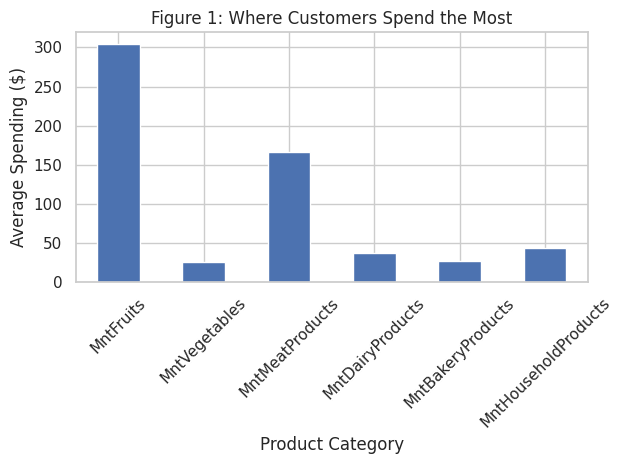

Figure 1 shows that customers spent the most on Fruits, with an average of $304.13, while Vegetables had the lowest average spending at $26.28. Fruit was therefore the largest spending category among the six categories.
Education
2n Cycle      10.95
Basic          3.70
Graduation    13.50
Master        15.41
PhD           20.82
Name: Campaign_Response, dtype: float64


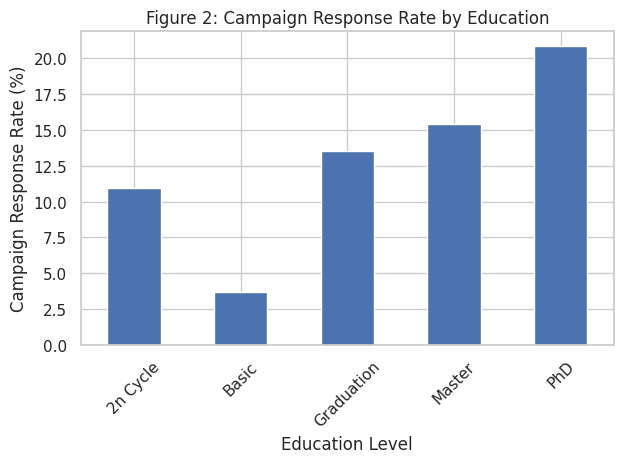

Figure 2 shows that customers with PhD education had the highest campaign response rate at 20.82%, while customers with Basic education had the lowest response rate at 3.70%. The response rate therefore differed across education groups.
Correlation between Recency and Total Spending: 0.021


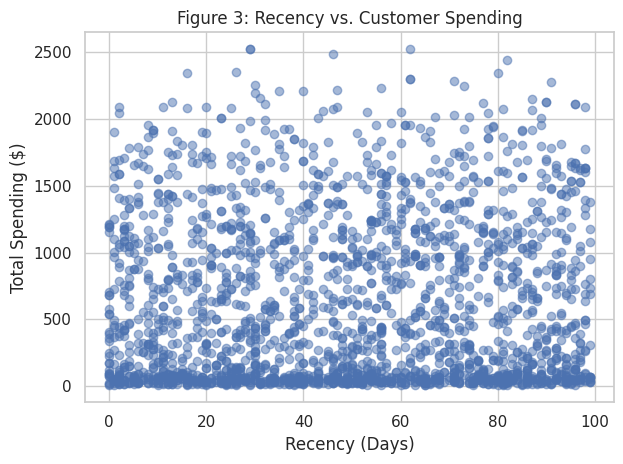

Figure 3 shows almost no linear relationship between recency and total customer spending, with a correlation coefficient of 0.021. Since this value is very close to zero, recency alone has very little linear relationship with total spending.
Total purchases by channel:
NumWebPurchases       9140
NumAppPurchases       5955
NumStorePurchases    12959
dtype: int64

Channel mix (%):
NumWebPurchases      32.58
NumAppPurchases      21.23
NumStorePurchases    46.19
dtype: float64


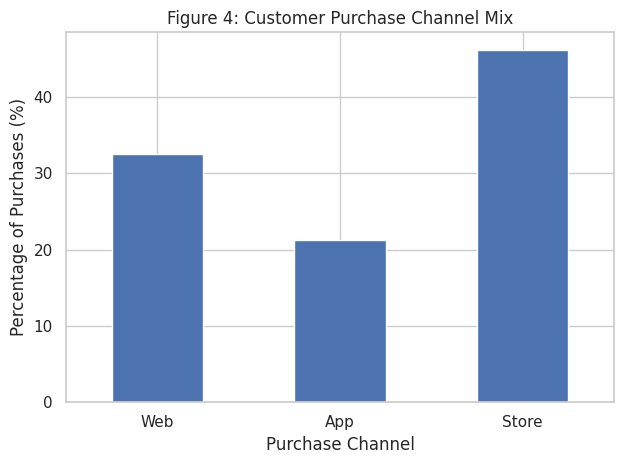

Figure 4 shows that Store was the most used purchase channel, accounting for 46.19% of purchases, while App had the lowest share at 21.23%. Store accounted for the largest share of purchases among the three channels.
Correlation with Campaign Response:
Total_Spending       0.266
Recency             -0.199
Total_Purchases      0.164
Income               0.161
NumWebPurchases      0.148
NumStorePurchases    0.039
Customer_Age        -0.019
NumWebVisitsMonth   -0.004
Name: Campaign_Response, dtype: float64


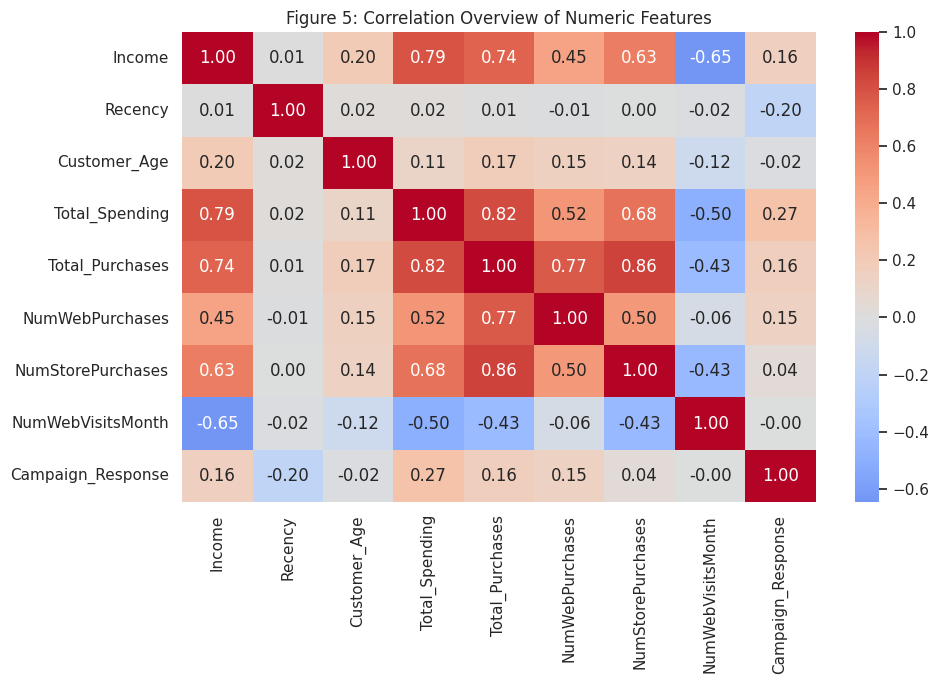

Figure 5 shows the correlations between the numeric features, where values range from -1 to +1. Values closer to +1 have a stronger positive relationship, while values closer to -1 have a stronger negative relationship. Total_Spending had the highest positive correlation with Campaign_Response at 0.27, while Recency had the strongest negative correlation at -0.20. Income and Total_Purchases both had correlations of 0.16 with Campaign_Response. Overall, Total_Spending had the strongest relationship with campaign response out of the numeric features shown.


In [ ]:
#Figure 1- spending across 6 product categories

import matplotlib.pyplot as plt
import seaborn as sns

spending_cols = [
    "MntFruits",
    "MntVegetables",
    "MntMeatProducts",
    "MntDairyProducts",
    "MntBakeryProducts",
    "MntHouseholdProducts"
]

# calculate average spending for each category
avg_spending = df_clean[spending_cols].mean()

print(avg_spending.round(2))

#  bar chart
avg_spending.plot(kind="bar")

plt.title("Figure 1: Where Customers Spend the Most")
plt.xlabel("Product Category")
plt.ylabel("Average Spending ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

highest = avg_spending.idxmax().replace("Mnt", "")
lowest = avg_spending.idxmin().replace("Mnt", "")

print(
    f"Figure 1 shows that customers spent the most on {highest}, "
    f"with an average of ${avg_spending.max():.2f}, while {lowest} "
    f"had the lowest average spending at ${avg_spending.min():.2f}. "
    f"Fruit was therefore the largest spending category among the six categories."
)




#Figure 2- campaign response rate by a demographic dimension of your choice
#choosing education

# calculate campaign response rate for each education level
education_response_rate = (
    df_clean.groupby("Education")["Campaign_Response"].mean() * 100
)
print(education_response_rate.round(2))

# bar chart
education_response_rate.plot(kind="bar")

plt.title("Figure 2: Campaign Response Rate by Education")
plt.xlabel("Education Level")
plt.ylabel("Campaign Response Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

highest = education_response_rate.idxmax()
lowest = education_response_rate.idxmin()

print(
    f"Figure 2 shows that customers with {highest} education had the highest "
    f"campaign response rate at {education_response_rate.max():.2f}%, while "
    f"customers with {lowest} education had the lowest response rate at "
    f"{education_response_rate.min():.2f}%. "
    f"The response rate therefore differed across education groups."
)


#Figure 3-recency vs. spending

# Calculate total spending across the six product categories
df_clean["Total_Spending"] = df_clean[
    [
        "MntFruits",
        "MntVegetables",
        "MntMeatProducts",
        "MntDairyProducts",
        "MntBakeryProducts",
        "MntHouseholdProducts"
    ]
].sum(axis=1)

# Calculate correlation between recency and total spending
recency_spending_corr = df_clean["Recency"].corr(df_clean["Total_Spending"])

print(f"Correlation between Recency and Total Spending: {recency_spending_corr:.3f}")

# Scatter plot
plt.scatter(df_clean["Recency"], df_clean["Total_Spending"], alpha=0.5)

plt.title("Figure 3: Recency vs. Customer Spending")
plt.xlabel("Recency (Days)")
plt.ylabel("Total Spending ($)")
plt.tight_layout()
plt.show()

print(
    f"Figure 3 shows almost no linear relationship between recency and "
    f"total customer spending, with a correlation coefficient of "
    f"{recency_spending_corr:.3f}. Since this value is very close to zero, "
    f"recency alone has very little linear relationship with total spending."
)

#Figure 4-channel mix (web / app / store)

# total purchases for each
channel_purchases = df_clean[
    ["NumWebPurchases", "NumAppPurchases", "NumStorePurchases"]
].sum()

# Calculate percentage of purchases
channel_mix = (channel_purchases / channel_purchases.sum()) * 100

print("Total purchases by channel:")
print(channel_purchases)

print("\nChannel mix (%):")
print(channel_mix.round(2))

#Bar chart
channel_mix.plot(kind="bar")

plt.title("Figure 4: Customer Purchase Channel Mix")
plt.xlabel("Purchase Channel")
plt.ylabel("Percentage of Purchases (%)")
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Web", "App", "Store"],
    rotation=0
)
plt.tight_layout()
plt.show()

# Reference
highest_channel = channel_mix.idxmax().replace("Num", "").replace("Purchases", "")
lowest_channel = channel_mix.idxmin().replace("Num", "").replace("Purchases", "")

print(
    f"Figure 4 shows that {highest_channel} was the most used purchase "
    f"channel, accounting for {channel_mix.max():.2f}% of purchases, while "
    f"{lowest_channel} had the lowest share at {channel_mix.min():.2f}%. "
    f"{highest_channel} accounted for the largest share of purchases "
    f"among the three channels."
)



#Figure 5-a correlation overview of the numeric features

correlation_features = [
    "Income",
    "Recency",
    "Customer_Age",
    "Total_Spending",
    "Total_Purchases",
    "NumWebPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Campaign_Response"
]

correlation_matrix = df_clean[correlation_features].corr()
response_correlations = (
    correlation_matrix["Campaign_Response"]
    .drop("Campaign_Response")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with Campaign Response:")
print(response_correlations.round(3))
# Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Figure 5: Correlation Overview of Numeric Features")
plt.tight_layout()
plt.show()

print(
    "Figure 5 shows the correlations between the numeric features, where values "
    "range from -1 to +1. Values closer to +1 have a stronger positive relationship, "
    "while values closer to -1 have a stronger negative relationship. "
    "Total_Spending had the highest positive correlation with Campaign_Response at 0.27, "
    "while Recency had the strongest negative correlation at -0.20. "
    "Income and Total_Purchases both had correlations of 0.16 with Campaign_Response. "
    "Overall, Total_Spending had the strongest relationship with campaign response "
    "out of the numeric features shown."
)


## 3. Classification and model evaluation

**Prediction target:** `Campaign_Response`. The dataset has an imbalanced target, so performance is assessed beyond accuracy alone.


### Majority-class baseline


In [ ]:
# y = df_clean['Campaign_Response']
# baseline_acc = 1 - y.mean()   # <-- what is this number? Keep it in view.

y = df_clean['Campaign_Response']

baseline_acc = 1 - y.mean()

print(f"Baseline Accuracy: {baseline_acc:.2%}") #remem this 85.06%

Baseline Accuracy: 85.06%


### Preprocessing and train/test split


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
#ML libraries

# Customer_ID, Membership_Date, and AcceptedPromo columns are not used as
# predictors
feature_cols = [
    "Customer_Age",
    "Education",
    "Marital_Status",
    "Income",
    "Kidhome",
    "Teenhome",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumWebPurchases",
    "NumAppPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Complain"
]

X = df_clean[feature_cols]
y = df_clean["Campaign_Response"]

# Numerical variables to scale
num_cols = [
    "Customer_Age",
    "Income",
    "Kidhome",
    "Teenhome",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumWebPurchases",
    "NumAppPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Complain"
]

# Categorical variables to encode
cat_cols = [
    "Education",
    "Marital_Status"
]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ]
)

# Fit preprocessing on training data
X_train_preprocessed = preprocessor.fit_transform(X_train)

# Use the same fitted preprocessing on the test data
X_test_preprocessed = preprocessor.transform(X_test)


print("Training data shape:", X_train_preprocessed.shape)
print("Testing data shape:", X_test_preprocessed.shape)
print(f"Training positive response rate: {y_train.mean():.2%}")
print(f"Testing positive response rate: {y_test.mean():.2%}")

# 1. Categorical variables:
# Education and Marital_Status contain words instead of numbers.
# I converted these categories into numerical columns so the models
# could use them.

# 2. Scaling:
# I standardized the numerical features so they are on a similar scale.
#KNN and SVM can be affected when some features have much larger values than others.

# 3. Stratified split:
# Only about 15% of customers responded to a campaign, so there are
# many more non-responders than responders. I used a stratified split
# to keep a similar percentage of responders in both sets.
# Training had 14.93% responders and testing had 14.96%.

# 4. Random seed:
# I used random_state=42 so I get the same data split each time


Training data shape: (1788, 24)
Testing data shape: (448, 24)
Training positive response rate: 14.93%
Testing positive response rate: 14.96%


### KNN, SVM, and Logistic Regression


In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score


# Test different k values using the training data
k_values = [3, 5, 7, 9, 11]
k_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        X_train_preprocessed,
        y_train,
        cv=5,
        scoring="f1"
    )

    k_scores.append(scores.mean())

# Choose the k with the highest average F1 score
best_k = k_values[k_scores.index(max(k_scores))]

print("Best k:", best_k)
print(f"Best average F1 score: {max(k_scores):.3f}")

# Train KNN using the selected k
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_preprocessed, y_train)
# In KNN, k is the number of nearby customers used to make a prediction.
# I tested different k values to see which worked best for this dataset.
# k=3 gave the highest F1 score of 0.352, so I used k=3 for my KNN model.

svm_model = SVC(kernel="rbf")
svm_model.fit(X_train_preprocessed, y_train)
# I chose the RBF kernel because it can handle more complex patterns
# between customer features and whether or not they respond to a campaign.


#third model logistic regression
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
# asked which model is best
log_model.fit(X_train_preprocessed, y_train)
# I chose Logistic Regression as my third model because it is gives me simpler model to compare with
# KNN and RBF SVM. It also uses regularization which helps reduce overfitting.



Best k: 3
Best average F1 score: 0.352


LogisticRegression(max_iter=1000, random_state=42)

Performance Comparison


,Model,Accuracy,F1 Score
0,Baseline,0.851,0.000
1,KNN,0.857,0.347
2,SVM,0.877,0.353
3,Logistic Regression,0.868,0.379



Best model based on F1 Score: Logistic Regression


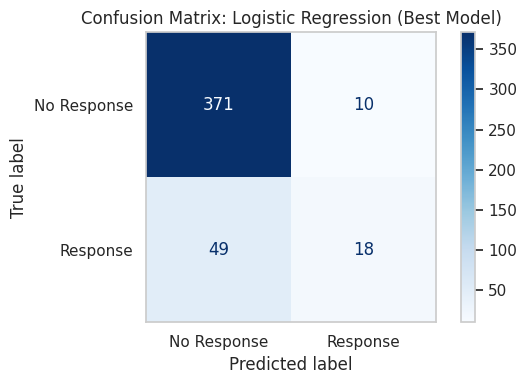

Top features driving Logistic Regression predictions:


,Feature,Coefficient,Strength
5,num__Total_Spending,0.923005,0.923005
22,cat__Marital_Status_Together,-0.861153,0.861153
19,cat__Marital_Status_Married,-0.763072,0.763072
4,num__Recency,-0.730314,0.730314
13,cat__Education_Basic,-0.679025,0.679025
10,num__NumWebVisitsMonth,0.655096,0.655096
9,num__NumStorePurchases,-0.621636,0.621636
3,num__Teenhome,-0.538275,0.538275
16,cat__Education_PhD,0.497667,0.497667
23,cat__Marital_Status_Widow,0.490250,0.490250


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


knn_pred = knn_model.predict(X_test_preprocessed)
svm_pred = svm_model.predict(X_test_preprocessed)
log_pred = log_model.predict(X_test_preprocessed)

knn_acc = accuracy_score(y_test, knn_pred)
knn_f1 = f1_score(y_test, knn_pred)

svm_acc = accuracy_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

log_acc = accuracy_score(y_test, log_pred)
log_f1 = f1_score(y_test, log_pred)

results = pd.DataFrame({
    "Model": ["Baseline", "KNN", "SVM", "Logistic Regression"],
    "Accuracy": [baseline_acc, knn_acc, svm_acc, log_acc],
    "F1 Score": [0.0, knn_f1, svm_f1, log_f1]
})

print("Performance Comparison")
display(results.round(3))

model_predictions = {
    "KNN": (knn_f1, knn_pred),
    "SVM": (svm_f1, svm_pred),
    "Logistic Regression": (log_f1, log_pred)
}

best_model = max(model_predictions, key=lambda x: model_predictions[x][0])
best_pred = model_predictions[best_model][1]

print(f"\nBest model based on F1 Score: {best_model}")

cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Response", "Response"]
).plot(ax=ax, cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix: {best_model} (Best Model)")
plt.grid(False)
plt.tight_layout()
plt.show()

# Features driving Logistic Regression predictions

feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": log_model.coef_[0]
})

coefficients["Strength"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values("Strength", ascending=False)

print("Top features driving Logistic Regression predictions:")
display(coefficients.head(10))

### Model interpretation and campaign implications

Compare model errors, inspect influential features, and consider the implications of campaign targeting.
